In [5]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import time
import matplotlib.pyplot as plt

**loading dataset from sklearn datasets**

In [2]:
data = load_breast_cancer()
X, y = data.data, data.target

**split into train and test sets**

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**tree counts to test**

In [10]:
tree_counts = [20, 50, 100, 200, 500]
results = []
accuracies = []
train_times = []

**model training, testing and evaluation for each tree count**

In [11]:
for n in tree_counts:
    # Initialize Random Forest with specific n_estimators
    rf = RandomForestClassifier(n_estimators=n, random_state=42)
    
    # Measure training time
    start_time = time.time()
    rf.fit(X_train, y_train)
    train_time = time.time() - start_time
    
    # Predict and evaluate
    y_pred = rf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    
    accuracies.append(acc)
    train_times.append(train_time)
    
    print(f"{n:<10} | {acc:.4f}     | {train_time:.4f}")

20         | 0.9649     | 0.0518
50         | 0.9649     | 0.0681
100        | 0.9649     | 0.1262
200        | 0.9649     | 0.2555
500        | 0.9649     | 0.6528


**Visualization**

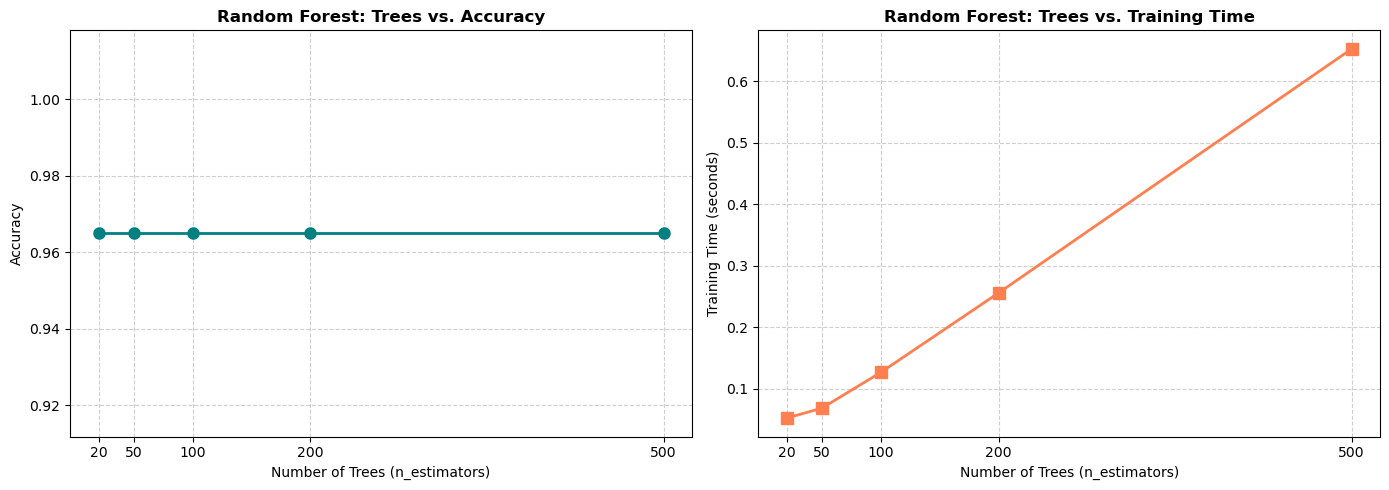

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Number of Trees vs Accuracy
ax1.plot(tree_counts, accuracies, marker='o', color='teal', linestyle='-', linewidth=2, markersize=8)
ax1.set_title('Random Forest: Trees vs. Accuracy', fontsize=12, fontweight='bold')
ax1.set_xlabel('Number of Trees (n_estimators)', fontsize=10)
ax1.set_ylabel('Accuracy', fontsize=10)
ax1.set_xticks(tree_counts)
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot 2: Number of Trees vs Training Time
ax2.plot(tree_counts, train_times, marker='s', color='coral', linestyle='-', linewidth=2, markersize=8)
ax2.set_title('Random Forest: Trees vs. Training Time', fontsize=12, fontweight='bold')
ax2.set_xlabel('Number of Trees (n_estimators)', fontsize=10)
ax2.set_ylabel('Training Time (seconds)', fontsize=10)
ax2.set_xticks(tree_counts)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()